In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
from joblib import Parallel, delayed, parallel_config
from matplotlib import pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

from environments.classes.lindblad_env import Lindblad_Environment


In [2]:
Nb = 6

ENV_PARAMS = {
    #general
    "wc": 1.0,
    "wb": 1.0,

    "Nc": Nb * 3,
    "Nb": Nb,

    "kappa": 0.2,
    
    "dt": 0.05,
    "tau": 10,

    #for monte carlo
    "ntraj": 16,
    "seed": 42,

    #for SSE

    #for SAC
    "min_u": -0.3,
    "max_u": 0.3,

    "reward": "ergotropy_full",
    "reward_coeff": 1.0,

    "observation": "default",
}

In [3]:
def run(env, u):

    history = []

    while env.t < env.tau:
        result = env.step(u)
        history.append(result)

    return history

In [ ]:
lambda_cs = np.linspace(ENV_PARAMS["min_u"] * 3, 0, 50)

def simulate(lambda_c):
    return run(
        Lindblad_Environment(ENV_PARAMS),
        lambda_c
    )

with parallel_config(
    backend="loky",
    n_jobs=12,
    inner_max_num_threads=1
):
    lindblad_histories = Parallel(verbose=10)(
        delayed(simulate)(lam)
        for lam in lambda_cs
    )

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  2.3min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  4.4min
[Parallel(n_jobs=8)]: Done  13 out of  25 | elapsed:  4.4min remaining:  4.1min
[Parallel(n_jobs=8)]: Done  16 out of  25 | elapsed:  4.5min remaining:  2.5min
[Parallel(n_jobs=8)]: Done  19 out of  25 | elapsed:  6.2min remaining:  2.0min
[Parallel(n_jobs=8)]: Done  22 out of  25 | elapsed:  6.3min remaining:   51.4s
[Parallel(n_jobs=8)]: Done  25 out of  25 | elapsed:  6.6min finished


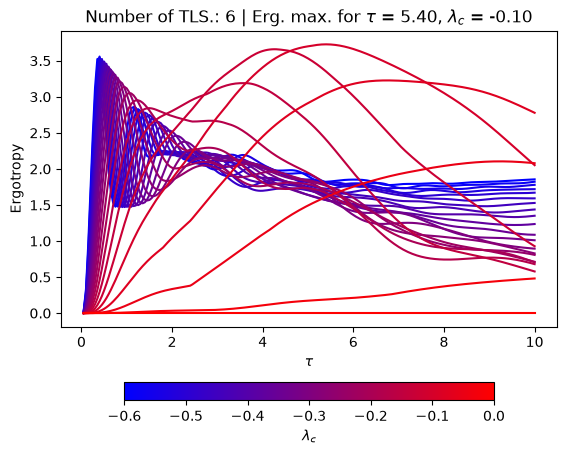

In [5]:
cmap = LinearSegmentedColormap.from_list(
    "blue_red", ["blue", "red"]
)

norm = Normalize(vmin=min(lambda_cs), vmax=max(lambda_cs))

fig, ax = plt.subplots()

time = [h["time"] for h in lindblad_histories[0]]

tau_max = []
erg_max = []
lcs_best = []

for i, lindblad_history in enumerate(lindblad_histories):

    ergotropy = [h["ergotropy_full"] for h in lindblad_history]

    idx = np.argmax(ergotropy)

    tau_max.append(time[idx])
    erg_max.append(ergotropy[idx])
    lcs_best.append(lambda_cs[i])

    color = cmap(norm(lambda_cs[i]))

    ax.plot(time, ergotropy, color=color)

ax.set_xlabel(r"$\tau$")
ax.set_ylabel("Ergotropy")

# Horizontal colorbar below the plot
sm = ScalarMappable(norm=norm, cmap=cmap)

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    pad=0.15,
    fraction=0.05
)

cbar.set_label(r"$\lambda_c$")

idx = np.argmax(erg_max)
best_tau = tau_max[idx]
best_lc = lcs_best[idx]

plt.title("Number of TLS.: " + str(ENV_PARAMS["Nb"]) + " | Erg. max. for " + r"$\tau$ = " + f"{best_tau:.2f}" + ", " + r"$\lambda_c$" + " = " + f"{best_lc:.2f}")

plt.show()

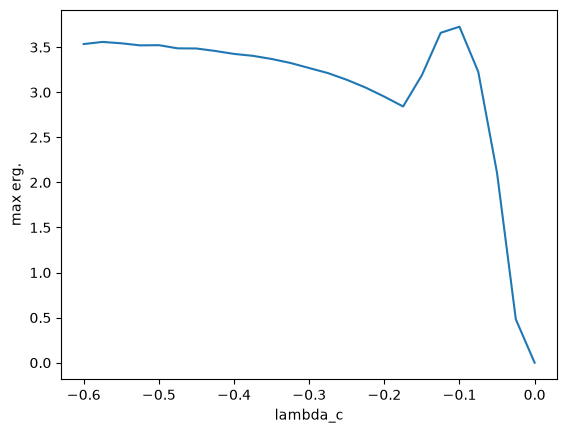

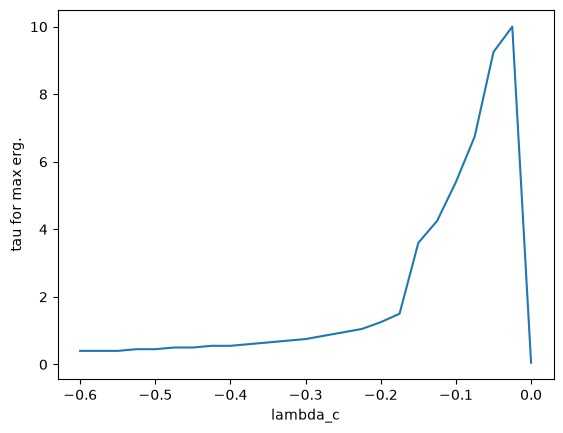

5.399999999999989 -0.10000000000000003


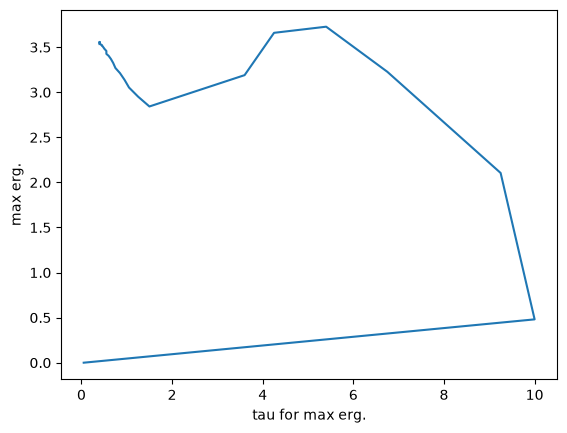

In [6]:
plt.plot(lcs_best, erg_max)

plt.xlabel("lambda_c")
plt.ylabel("max erg.")
plt.show()

plt.plot(lcs_best, tau_max)

plt.xlabel("lambda_c")
plt.ylabel("tau for max erg.")
plt.show()

plt.plot(tau_max, erg_max)

plt.xlabel("tau for max erg.")
plt.ylabel("max erg.")

idx = np.argmax(erg_max)
print(tau_max[idx], lcs_best[idx])

plt.show()
